<a href="https://colab.research.google.com/github/Pwpszprog/useful_programs_paw/blob/main/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Colab Intro

$$
S_n = a_1 \cdot \frac{1-q^n}{1-q}
$$

$$
\begin{align*}
\nabla \cdot \mathbf{E} &= \frac{\rho}{\varepsilon_0} && \text{(Prawo Gaussa dla elektryczności)} \\[8pt]
\nabla \cdot \mathbf{B} &= 0 && \text{(Prawo Gaussa dla magnetyzmu)} \\[8pt]
\nabla \times \mathbf{E} &= -\frac{\partial \mathbf{B}}{\partial t} && \text{(Prawo indukcji Faradaya)} \\[8pt]
\nabla \times \mathbf{B} &= \mu_0 \mathbf{J} + \mu_0 \varepsilon_0 \frac{\partial \mathbf{E}}{\partial t} && \text{(Prawo Ampère'a--Maxwella)}
\end{align*}
$$

In [ ]:
a = 2+2
print(a)

4


In [ ]:
import math


a = math.pi*math.pi
b = math.pi**2

print(a)
print(b)

9.869604401089358
9.869604401089358


In [ ]:
import base64
import requests
from google.colab import userdata

# 1. Obliczenie sumy kwadratów liczb od 1 do 100 (wynik: 338350)
n = 100
suma_kwadratow = sum(i**2 for i in range(1, n + 1))
zawartosc = f"Suma kwadratów liczb od 1 do {n} wynosi: {suma_kwadratow}\n"

# 2. Zapis lokalny w środowisku Colab
filename = "colab_wynik.txt"
with open(filename, "w", encoding="utf-8") as f:
    f.write(zawartosc)

# 3. Kodowanie zawartości pliku do Base64
with open(filename, "rb") as f:
    encoded_content = base64.b64encode(f.read()).decode("utf-8")

# 4. Parametry integracji z GitHubem
GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")
REPO_OWNER = "Pwpszprog"
REPO_NAME = "useful_programs_paw"
FILE_PATH = f"pages/solutions/02_sol_colab/{filename}"

url = f"https://api.github.com/repos/{REPO_OWNER}/{REPO_NAME}/contents/{FILE_PATH}"
headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json",
}

# Pobranie identyfikatora SHA pliku do nadpisania na GitHubie
get_res = requests.get(url, headers=headers)
sha = get_res.json().get("sha") if get_res.status_code == 200 else None

data = {
    "message": f"Zapis sumy kwadratów od 1 do {n}",
    "content": encoded_content,
    "branch": "main",
}
if sha:
    data["sha"] = sha

# 5. Wysyłka pliku do repozytorium
response = requests.put(url, headers=headers, json=data)

if response.status_code in [200, 201]:
    print(f"Plik {filename} został zaktualizowany w repozytorium!")
    print(f"Zapisana treść:\n{zawartosc}")
else:
    print(
        f"Wystąpił błąd ({response.status_code}):",
        response.json().get("message"),
    )

Plik colab_wynik.txt został zaktualizowany w repozytorium!
Zapisana treść:
Suma kwadratów liczb od 1 do 100 wynosi: 338350



In [ ]:
import base64
import io
import matplotlib.pyplot as plt
import numpy as np
import requests

# 1. Generowanie wykresu
k = np.arange(1, 21)
y = k**2

plt.figure(figsize=(8, 5))
plt.plot(
    k, y, marker="o", linestyle="-", color="#1f77b4", label="$y = k^2$"
)
plt.title(r"Wykres funkcji $k^2$ dla $k \in [1, 20]$")
plt.xlabel("k")
plt.ylabel("$k^2$")
plt.xticks(k)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# 2. Zapis wykresu bezpośrednio do pamięci w formacie PNG
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
plt.close()

# Zakodowanie zawartości binarnej obrazu do Base64
encoded_content = base64.b64encode(buffer.getvalue()).decode("utf-8")

# 3. Ustawienia GitHub API
try:
    from google.colab import userdata

    GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")
except ImportError:
    GITHUB_TOKEN = "TWÓJ_NOWY_GITHUB_TOKEN"

REPO_OWNER = "Pwpszprog"
REPO_NAME = "useful_programs_paw"
FILE_PATH = (
    "pages/solutions/02_sol_colab/wykres.png"  # Ścieżka i nazwa pliku na GitHubie
)

url = f"https://api.github.com/repos/{REPO_OWNER}/{REPO_NAME}/contents/{FILE_PATH}"
headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json",
}

# Pobranie SHA (wymagane, jeśli plik już istnieje i ma zostać nadpisany)
get_response = requests.get(url, headers=headers)
sha = get_response.json().get("sha") if get_response.status_code == 200 else None

data = {
    "message": "Dodano wykres k^2 (wykres.png)",
    "content": encoded_content,
}
if sha:
    data["sha"] = sha

# 4. Wysyłanie pliku do GitHub
response = requests.put(url, headers=headers, json=data)

if response.status_code in [200, 201]:
    print("Wykres został pomyślnie zapisany w repozytorium GitHub!")
else:
    print(
        f"Wystąpił błąd ({response.status_code}):",
        response.json().get("message"),
    )

Wykres został pomyślnie zapisany w repozytorium GitHub!


In [ ]:
import base64
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
import requests
from google.colab import userdata
from scipy.integrate import solve_ivp

# 1. Symulacja fizyczna wahadła
g = 9.81
L = 1.0
theta0 = np.radians(60)
omega0 = 0.0
y0 = [theta0, omega0]

t_max = 5  # Czas trwania (5 s zapewnia optymalny rozmiar pliku GIF)
fps = 20
t_eval = np.linspace(0, t_max, t_max * fps)


def pendulum_ode(t, y):
    theta, omega = y
    return [omega, -(g / L) * np.sin(theta)]


sol = solve_ivp(pendulum_ode, (0, t_max), y0, t_eval=t_eval)
theta = sol.y[0]
x = L * np.sin(theta)
y = -L * np.cos(theta)

# 2. Tworzenie animacji Matplotlib
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-L * 1.2, L * 1.2)
ax.set_ylim(-L * 1.2, L * 0.3)
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_title("Symulacja wahadła")

(line,) = ax.plot(
    [], [], "o-", lw=3, color="#1f77b4", markersize=12, markerfacecolor="#d62728"
)


def init():
    line.set_data([], [])
    return (line,)


def animate(i):
    line.set_data([0, x[i]], [0, y[i]])
    return (line,)


anim = animation.FuncAnimation(
    fig, animate, init_func=init, frames=len(t_eval), interval=1000 / fps
)
plt.close(fig)

# 3. Zapis do pliku GIF
gif_filename = "video.gif"
anim.save(gif_filename, writer="pillow", fps=fps)

# 4. Kodowanie pliku binarnego do Base64
with open(gif_filename, "rb") as f:
    encoded_content = base64.b64encode(f.read()).decode("utf-8")

# 5. Wysyłanie pliku na GitHub
GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")
REPO_OWNER = "Pwpszprog"
REPO_NAME = "useful_programs_paw"
FILE_PATH = "pages/solutions/02_sol_colab/video.gif"

url = f"https://api.github.com/repos/{REPO_OWNER}/{REPO_NAME}/contents/{FILE_PATH}"
headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json",
}

# Pobranie SHA pliku (potrzebne do nadpisania, jeśli plik istnieje)
get_response = requests.get(url, headers=headers)
sha = get_response.json().get("sha") if get_response.status_code == 200 else None

data = {
    "message": "Dodano animację wahadła (video.gif)",
    "content": encoded_content,
}
if sha:
    data["sha"] = sha

response = requests.put(url, headers=headers, json=data)

if response.status_code in [200, 201]:
    print("Plik video.gif został pomyślnie zapisany w repozytorium GitHub!")
else:
    print(
        f"Wystąpił błąd ({response.status_code}):",
        response.json().get("message"),
    )

Plik video.gif został pomyślnie zapisany w repozytorium GitHub!


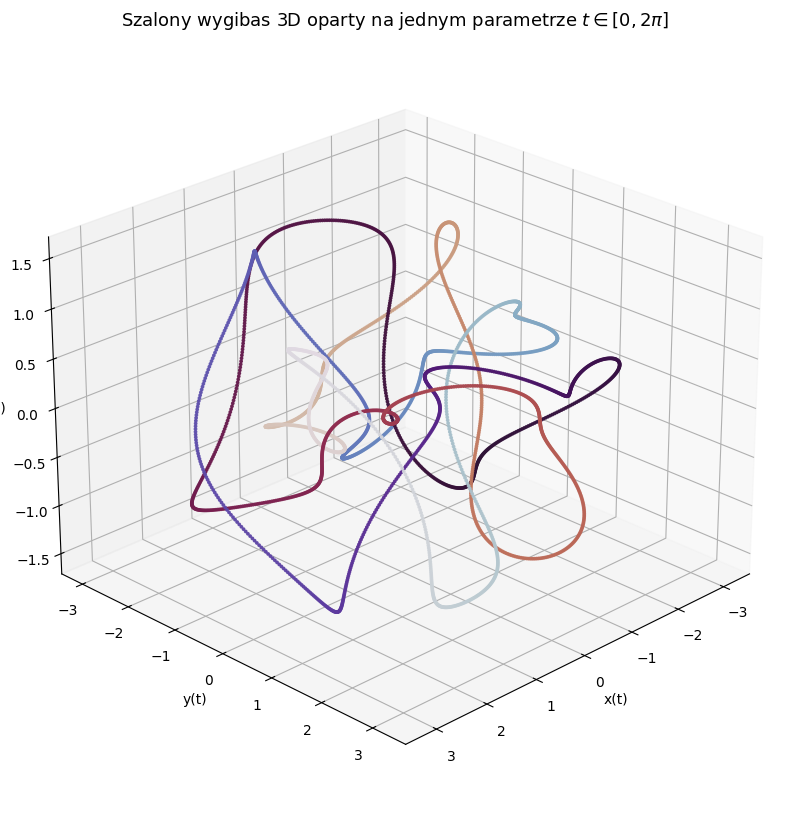

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# Parametric equations
t = np.linspace(0, 2 * np.pi, 3000)
r = 2 + np.sin(7 * t)
x = r * np.cos(3 * t) + 0.3 * np.sin(23 * t)
y = r * np.sin(3 * t) + 0.3 * np.cos(23 * t)
z = np.cos(7 * t) + 0.5 * np.sin(11 * t)

# 3D Plot
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(x, y, z, c=t, cmap="twilight", s=3, alpha=0.9)
ax.plot(x, y, z, color="black", lw=0.3, alpha=0.4)
ax.set_title(
    r"Szalony wygibas 3D oparty na jednym parametrze $t \in [0, 2\pi]$",
    fontsize=13,
)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.view_init(elev=25, azim=45)
ax.grid(True, linestyle="--", alpha=0.3)

plt.show()